# 01 · Train a TD3 policy on MuJoCo Reacher

A 2-joint arm must touch a random target. We train **TD3** (Stable-Baselines3 + PyTorch) headless on the GPU, then compare the learned policy to a random one.

All logic lives in `scripts/train.py`; this notebook just drives it and plots the results. Set the environment variable `DFC_QUICK=1` before launching Jupyter for a tiny smoke-test run.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "envs" / "stress_wrappers.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

QUICK = os.environ.get("DFC_QUICK", "0") == "1"  # DFC_QUICK=1 -> tiny budgets, for smoke-testing only
PLOTS = ROOT / "plots" / ("quick" if QUICK else "")
PLOTS.mkdir(parents=True, exist_ok=True)

print("project root :", ROOT.name)
print("CUDA         :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available (cpu only)")
print("quick mode   :", QUICK)

project root : deep-feedback-control
CUDA         : NVIDIA GeForce RTX 3070 Ti Laptop GPU
quick mode   : False


## Configuration
Hyperparameters come from `configs/td3_config.yaml`.

In [2]:
from scripts.train import load_config, train, model_file
from scripts.evaluate_ipqc import run_episode, RandomPolicy
from envs import make_base_env

cfg = load_config()
if QUICK:
    TIMESTEPS, LEARNING_STARTS, MODEL_PATH = 3000, 500, "models/reacher_td3_quick"
else:
    TIMESTEPS, LEARNING_STARTS, MODEL_PATH = None, None, None  # use the values in the config file

pd.Series({k: v for k, v in cfg.items() if k != "ipqc"}, name="td3_config").to_frame()

,td3_config
env_id,Reacher-v4
seed,0
total_timesteps,150000
learning_rate,0.001
batch_size,256
buffer_size,200000
learning_starts,5000
device,cuda
action_noise_sigma,0.1
model_path,models/reacher_td3


## Train
150k steps took about 37 minutes on an RTX 3070 Ti laptop. Training is silent; the curve below is read back from the Monitor log.

In [3]:
result = train(cfg, timesteps=TIMESTEPS, learning_starts=LEARNING_STARTS, model_path=MODEL_PATH, verbose=0)
print("device:", result.model.device, "| saved:", model_file(result.model_path).relative_to(ROOT))

site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment Reacher-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


device: cuda | saved: models\reacher_td3.zip


## Training curve

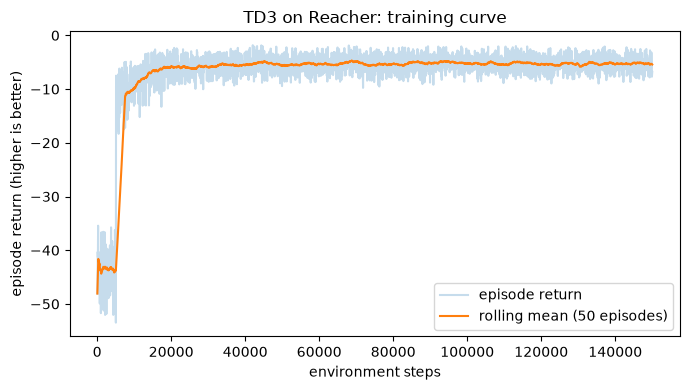

In [4]:
log = pd.read_csv(result.monitor_path, skiprows=1)  # columns: r = return, l = length, t = wall time
log["timesteps"] = log["l"].cumsum()
log["rolling_return"] = log["r"].rolling(50, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(log["timesteps"], log["r"], alpha=0.25, label="episode return")
ax.plot(log["timesteps"], log["rolling_return"], label="rolling mean (50 episodes)")
ax.set_xlabel("environment steps")
ax.set_ylabel("episode return (higher is better)")
ax.set_title("TD3 on Reacher: training curve")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "training_curve.png", dpi=150)
plt.show()

## Trained vs. random policy
Twenty evaluation episodes each, deterministic policy, no stress.

In [5]:
env = make_base_env(cfg["env_id"])
trained = [run_episode(env, result.model, seed=0 if i == 0 else None) for i in range(20)]
rand_policy = RandomPolicy(env.action_space, seed=0)
random_ = [run_episode(env, rand_policy, seed=0 if i == 0 else None) for i in range(20)]

print(f"trained policy : {np.mean(trained):7.2f} ± {np.std(trained):.2f}")
print(f"random policy  : {np.mean(random_):7.2f} ± {np.std(random_):.2f}")

site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment Reacher-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


trained policy :   -3.84 ± 1.52
random policy  :  -43.48 ± 4.15


**Next:** `02_ipqc_stress_test.ipynb` loads this model and measures how far each failure mode can go before performance collapses.